[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.1/Problem_1.3.ipynb)

# Chapter 1, Problem 3 — building a spacetime diagram

**Problem (paraphrased).** Draw the $t$ and $x$ axes of an observer $\mathcal{O}$, then draw:

- **(a)** the world line of $\mathcal{O}$'s clock at $x = 1\ \text{m}$;
- **(b)** the world line of a particle moving with $dx/dt = 0.1$ that is at $x = 0.5\ \text{m}$ when $t = 0$;
- **(c)** the $\bar t$ and $\bar x$ axes of an observer $\bar{\mathcal O}$ moving at $v = 0.5$ in the $+x$ direction relative to $\mathcal O$, with the same origin;
- **(d)** the locus of events whose interval from the origin is $\Delta s^2 = -1\ \text{m}^2$;
- **(e)** the locus of events whose interval from the origin is $\Delta s^2 = +1\ \text{m}^2$;
- **(f)** the calibration ticks at 1 m intervals along the $\bar x$ and $\bar t$ axes;
- **(g)** the locus of events whose interval from the origin is $\Delta s^2 = 0$;
- **(h)** the locus of events all occurring at $t = 2\ \text{m}$ (simultaneous for $\mathcal O$);
- **(i)** the locus of events all occurring at $\bar t = 2\ \text{m}$ (simultaneous for $\bar{\mathcal O}$);
- **(j)** the event at $\bar t = 0$, $\bar x = 0.5\ \text{m}$;
- **(k)** the locus of events $\bar x = 1\ \text{m}$;
- **(l)** the world line of a photon emitted from the event $t = -1\ \text{m}$, $x = 0$, travelling in the $-x$ direction, reflected when it meets a mirror at $\bar x = -1\ \text{m}$, and absorbed when it meets a detector at $x = 0.75\ \text{m}$.

Conventions: $c = 1$, so both axes are in metres and light travels at $45^\circ$. $\Delta s^2 = -\Delta t^2 + \Delta x^2$ (Schutz's sign convention, eq. 1.1).

Each part below has the derivation, then a diagram that adds that part (earlier parts are kept, faded). The full diagram is at the end.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from schutz_gr import gamma, lorentz, inverse_lorentz, interval_tx
from schutz_gr.diagrams import SpacetimeDiagram, COLORS

%config InlineBackend.figure_format = 'retina'

v = sp.Rational(1, 2)           # Ō's velocity relative to O
g = gamma(v)                    # exact: 2/sqrt(3)
print("gamma =", g, "=", sp.N(g, 6))
t, x = sp.symbols("t x", real=True)

gamma = 2*sqrt(3)/3 = 1.15470


In [3]:
# One function draws any subset of the parts, so each section can show its own addition.
VF = float(v)
GF = float(g)
ORDER = "abcdefghijkl"

def draw(parts, highlight=None, title=None, xlim=(-3, 3.5), tlim=(-3, 3.5)):
    d = SpacetimeDiagram(xlim=xlim, tlim=tlim, title=title, size=7)
    def a(p):  # alpha: faded unless highlighted
        return 1.0 if (highlight is None or p == highlight) else 0.35
    def lab(p, text):
        return text if (highlight is None or p == highlight) else None
    if "g" in parts:
        d.light_cone(label=lab("g", "(g) Δs² = 0: light cone t = ±x"), color="gold",
                     shade=(highlight in (None, "g")))
    if "a" in parts:
        d.world_line(lambda T: 1 + 0 * T, color="teal", alpha=a("a"),
                     label=lab("a", "(a) O's clock: x = 1"))
    if "b" in parts:
        d.world_line(lambda T: 0.5 + 0.1 * T, color="green", alpha=a("b"),
                     label=lab("b", "(b) particle: x = 0.5 + 0.1 t"))
    if "c" in parts:
        d.boosted_axes(VF, color="amber", ticks=3 if "f" in parts else 0,
                       label=lab("c", "(c) Ō axes: x = t/2 and t = x/2") or "")
        if "f" in parts and highlight in (None, "f"):
            h = d.ax.scatter([], [], s=22, color=COLORS["amber"], edgecolor=COLORS["bg"],
                             label="(f) ticks: t̄ = n at (γn, γvn), x̄ = n at (γvn, γn)")
            d._legend_handles.append(h)
    if "d" in parts:
        d.hyperbola(-1, color="violet", label=lab("d", "(d) Δs² = −1: t² − x² = 1"))
        for ln in d.ax.lines[-2:]: ln.set_alpha(a("d"))
    if "e" in parts:
        d.hyperbola(+1, color="rose", label=lab("e", "(e) Δs² = +1: x² − t² = 1"))
        for ln in d.ax.lines[-2:]: ln.set_alpha(a("e"))
    if "h" in parts:
        d.simultaneity_line(lambda X: 2 + 0 * X, color="teal", ls="--", lw=1.6, alpha=a("h"),
                            label=lab("h", "(h) O-simultaneous: t = 2"))
    if "i" in parts:
        d.simultaneity_line(lambda X: VF * X + 2 / GF, color="amber", ls="--", lw=1.6, alpha=a("i"),
                            label=lab("i", "(i) Ō-simultaneous: t̄ = 2"))
    if "j" in parts:
        tj, xj = inverse_lorentz(0, 0.5, VF)
        d.event(float(tj), float(xj), name="(j)", color="text")
    if "k" in parts:
        d.world_line(lambda T: VF * T + 1 / GF, color="violet", ls="-.", lw=1.6, alpha=a("k"),
                     label=lab("k", "(k) x̄ = 1: x = t/2 + √3/2"))
    if "l" in parts:
        r3 = np.sqrt(3)
        tR, xR = (r3 - 2) / 3, -(r3 + 1) / 3
        tD = (8 * r3 + 5) / 12
        al = a("l")
        d.world_line(lambda T: VF * T - 1 / GF, color="grey", ls=":", lw=1.5, alpha=al,
                     label=lab("l", "(l) mirror at x̄ = −1"))
        d.world_line(lambda T: 0.75 + 0 * T, color="grey", ls="--", lw=1.2, alpha=al,
                     label=lab("l", "(l) detector at x = 0.75"))
        d.line([0, xR], [-1, tR], color="gold", lw=2.6, alpha=al, label=lab("l", "(l) photon"))
        d.line([xR, 0.75], [tR, tD], color="gold", lw=2.6, alpha=al)
        if highlight in (None, "l"):
            d.event(-1, 0, name="emit", color="gold", offset=(6, -12))
            d.event(tR, xR, name="reflect", color="gold", offset=(-52, 6))
            d.event(tD, 0.75, name="absorb", color="gold", offset=(6, 2))
    return d

## (a) World line of $\mathcal O$'s clock at $x = 1\ \text{m}$

A world line is the set of events a body occupies. The clock belongs to $\mathcal O$'s lattice of synchronized clocks, so it is **at rest** in $\mathcal O$'s frame: its position never changes.

$$
\text{world line (a)}:\quad x = 1\ \text{m},\qquad t\ \text{arbitrary}.
$$

On the diagram it is a vertical line through $x=1$. Every point on it is the clock at a different time. (Vertical ⇔ at rest in $\mathcal O$; this will matter in (c), where $\bar{\mathcal O}$'s clocks are *not* vertical.)

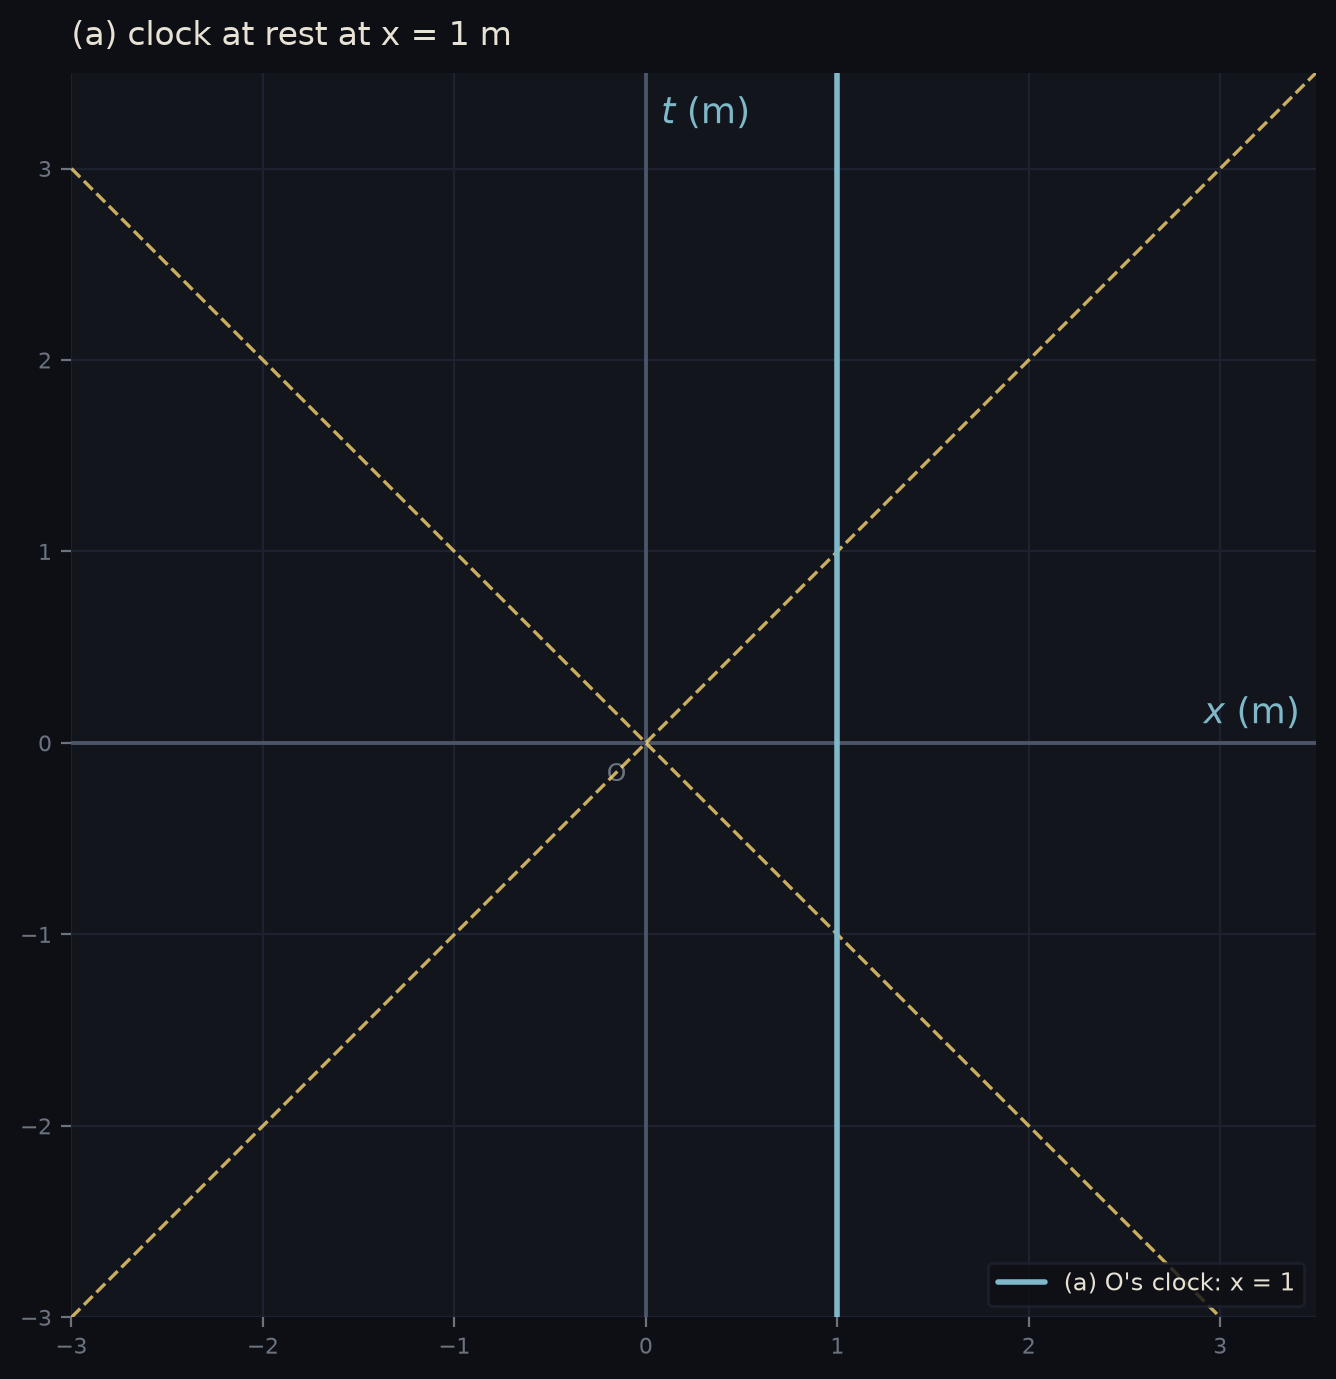

In [4]:
draw("ag", highlight="a", title="(a) clock at rest at x = 1 m").show()

## (b) Particle with $dx/dt = 0.1$, at $x = 0.5\ \text{m}$ when $t = 0$

Constant velocity ⇒ $x$ is linear in $t$. Integrate $dx/dt = 0.1$ with the initial condition $x(0) = 0.5$:

$$
x(t) = 0.5 + 0.1\,t \qquad\Longleftrightarrow\qquad t = 10\,(x - 0.5).
$$

On a diagram with $t$ vertical, the **slope** of a world line is $dt/dx = 1/v = 10$: steep, close to vertical, because $v = 0.1$ is slow. Compare light, $v=1$, slope $1$ ($45^\circ$). Every material body has $|v|<1$, so its world line is steeper than $45^\circ$, i.e. it stays *inside* the light cone of each of its events — part (g) shows the cone of the origin.

Sample events: $(t, x) = (0, 0.5),\ (1, 0.6),\ (-2, 0.3)$.

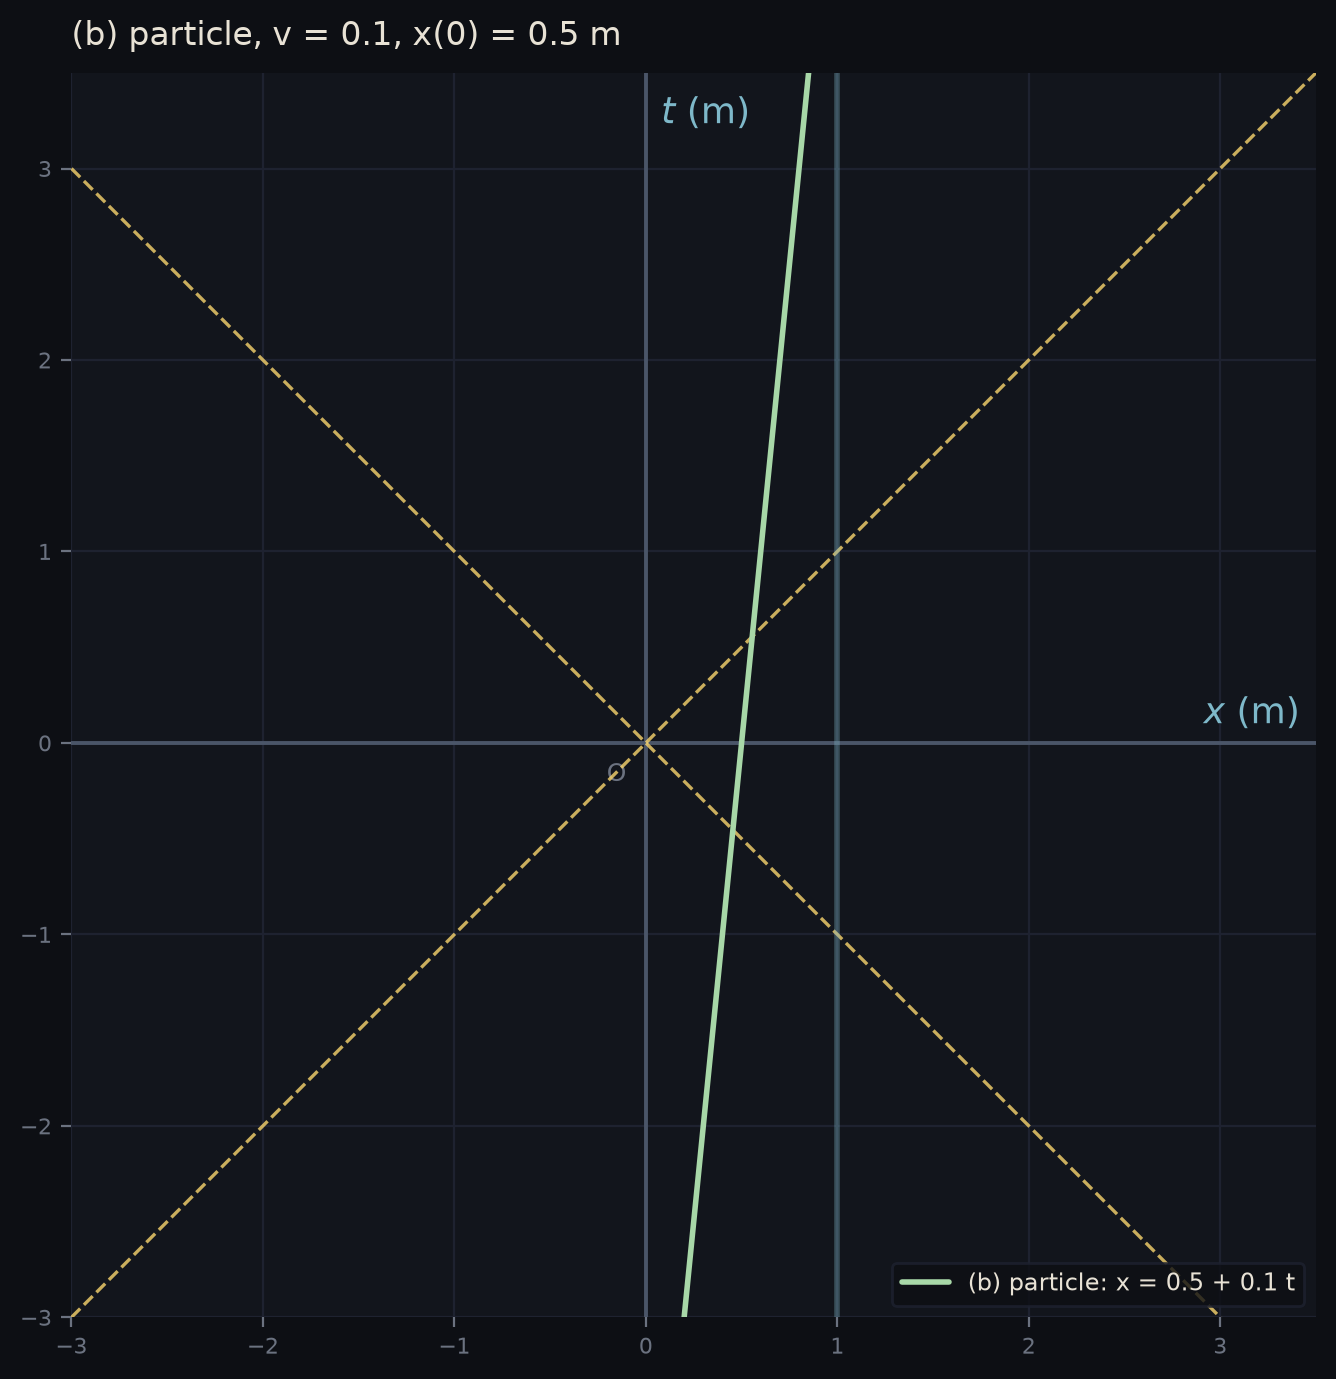

In [5]:
draw("abg", highlight="b", title="(b) particle, v = 0.1, x(0) = 0.5 m").show()

## (c) The $\bar t$ and $\bar x$ axes of $\bar{\mathcal O}$ ($v = 0.5$)

Use the Lorentz transformation (Schutz eq. 1.12) for $\bar{\mathcal O}$ moving at $v$ along $+x$, origins coinciding:

$$
\bar t = \gamma\,(t - v x),\qquad \bar x = \gamma\,(x - v t),\qquad \gamma = \frac{1}{\sqrt{1-v^2}} .
$$

**The $\bar t$ axis** is the set of events with $\bar x = 0$ (the world line of $\bar{\mathcal O}$'s spatial origin):
$$
\bar x = 0 \iff x - v t = 0 \iff \boxed{x = v\,t = 0.5\,t}\quad(\text{slope } dt/dx = 1/v = 2).
$$
That's just "the origin of $\bar{\mathcal O}$ moves at $v$" — as it must.

**The $\bar x$ axis** is the set of events with $\bar t = 0$ (all events $\bar{\mathcal O}$ calls simultaneous with the origin):
$$
\bar t = 0 \iff t - v x = 0 \iff \boxed{t = v\,x = 0.5\,x}\quad(\text{slope } dt/dx = v = 0.5).
$$

**Geometry.** The $\bar t$ axis makes angle $\arctan v$ with the $t$ axis; the $\bar x$ axis makes the *same* angle $\arctan v$ with the $x$ axis. They tilt symmetrically toward the light ray $t = x$, which bisects them. This is forced by the constancy of $c$: a light ray must be at "$45^\circ$" in *both* frames, i.e. must bisect each pair of axes (Schutz §1.5, Fig. 1.4).

**Not perpendicular — and that's fine.** The diagram is drawn in $\mathcal O$'s coordinates with Euclidean paper geometry; Minkowski geometry isn't Euclidean, so perpendicularity on paper means nothing for $\bar{\mathcal O}$.

t̄ = sqrt(3)*(2*t - x)/3    x̄ = sqrt(3)*(-t + 2*x)/3
t̄ axis (x̄ = 0): [t/2] -> x = t/2
x̄ axis (t̄ = 0): [x/2] -> t = x/2
angle of each axis from O's axis: arctan(0.5) = 26.57°


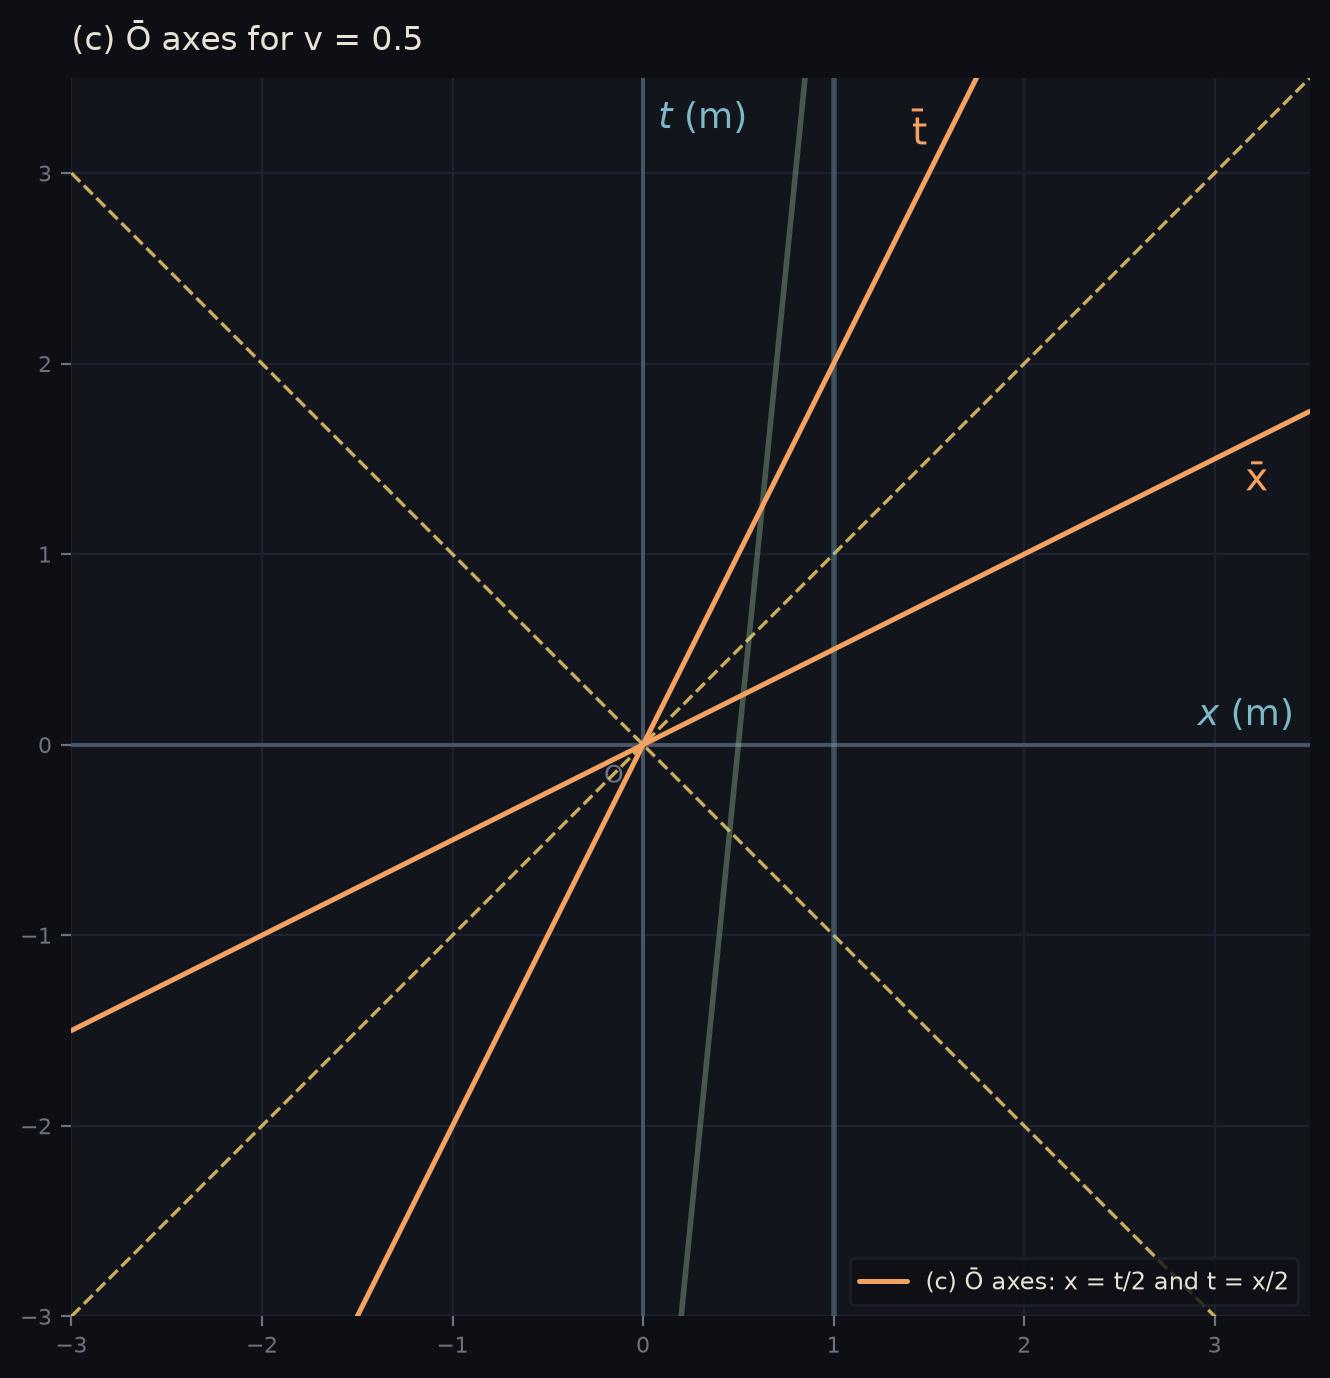

In [6]:
tb, xb = lorentz(t, x, v)
print("t̄ =", sp.simplify(tb), "   x̄ =", sp.simplify(xb))
print("t̄ axis (x̄ = 0):", sp.solve(sp.Eq(xb, 0), x), "-> x =", sp.solve(sp.Eq(xb, 0), x)[0])
print("x̄ axis (t̄ = 0):", sp.solve(sp.Eq(tb, 0), t), "-> t =", sp.solve(sp.Eq(tb, 0), t)[0])
print(f"angle of each axis from O's axis: arctan(0.5) = {np.degrees(np.arctan(0.5)):.2f}°")
draw("abcg", highlight="c", title="(c) Ō axes for v = 0.5").show()

## (d) Locus $\Delta s^2 = -1\ \text{m}^2$ from the origin

For an event $(t, x)$ (with $y = z = 0$), the interval from the origin is $\Delta s^2 = -t^2 + x^2$. Setting it to $-1$:

$$
-t^2 + x^2 = -1 \iff \boxed{t^2 - x^2 = 1}.
$$

This is a **hyperbola** with two branches, $t = +\sqrt{1+x^2}$ (future) and $t = -\sqrt{1+x^2}$ (past). Properties:

- vertices at $(t,x) = (\pm1, 0)$ — on $\mathcal O$'s time axis, one metre of proper time from the origin;
- asymptotes $t = \pm x$ — the light cone;
- every point is **timelike** separated from the origin ($\Delta s^2<0$): a clock moving uniformly from the origin to any point on the upper branch records proper time $\Delta\tau = \sqrt{-\Delta s^2} = 1$ m.

Because $\Delta s^2$ is invariant (§1.6), $\bar{\mathcal O}$ gets the same equation: $\bar t^2 - \bar x^2 = 1$. Check below.

t̄² − x̄² = t**2 - x**2  (identical to t² − x²: invariant)


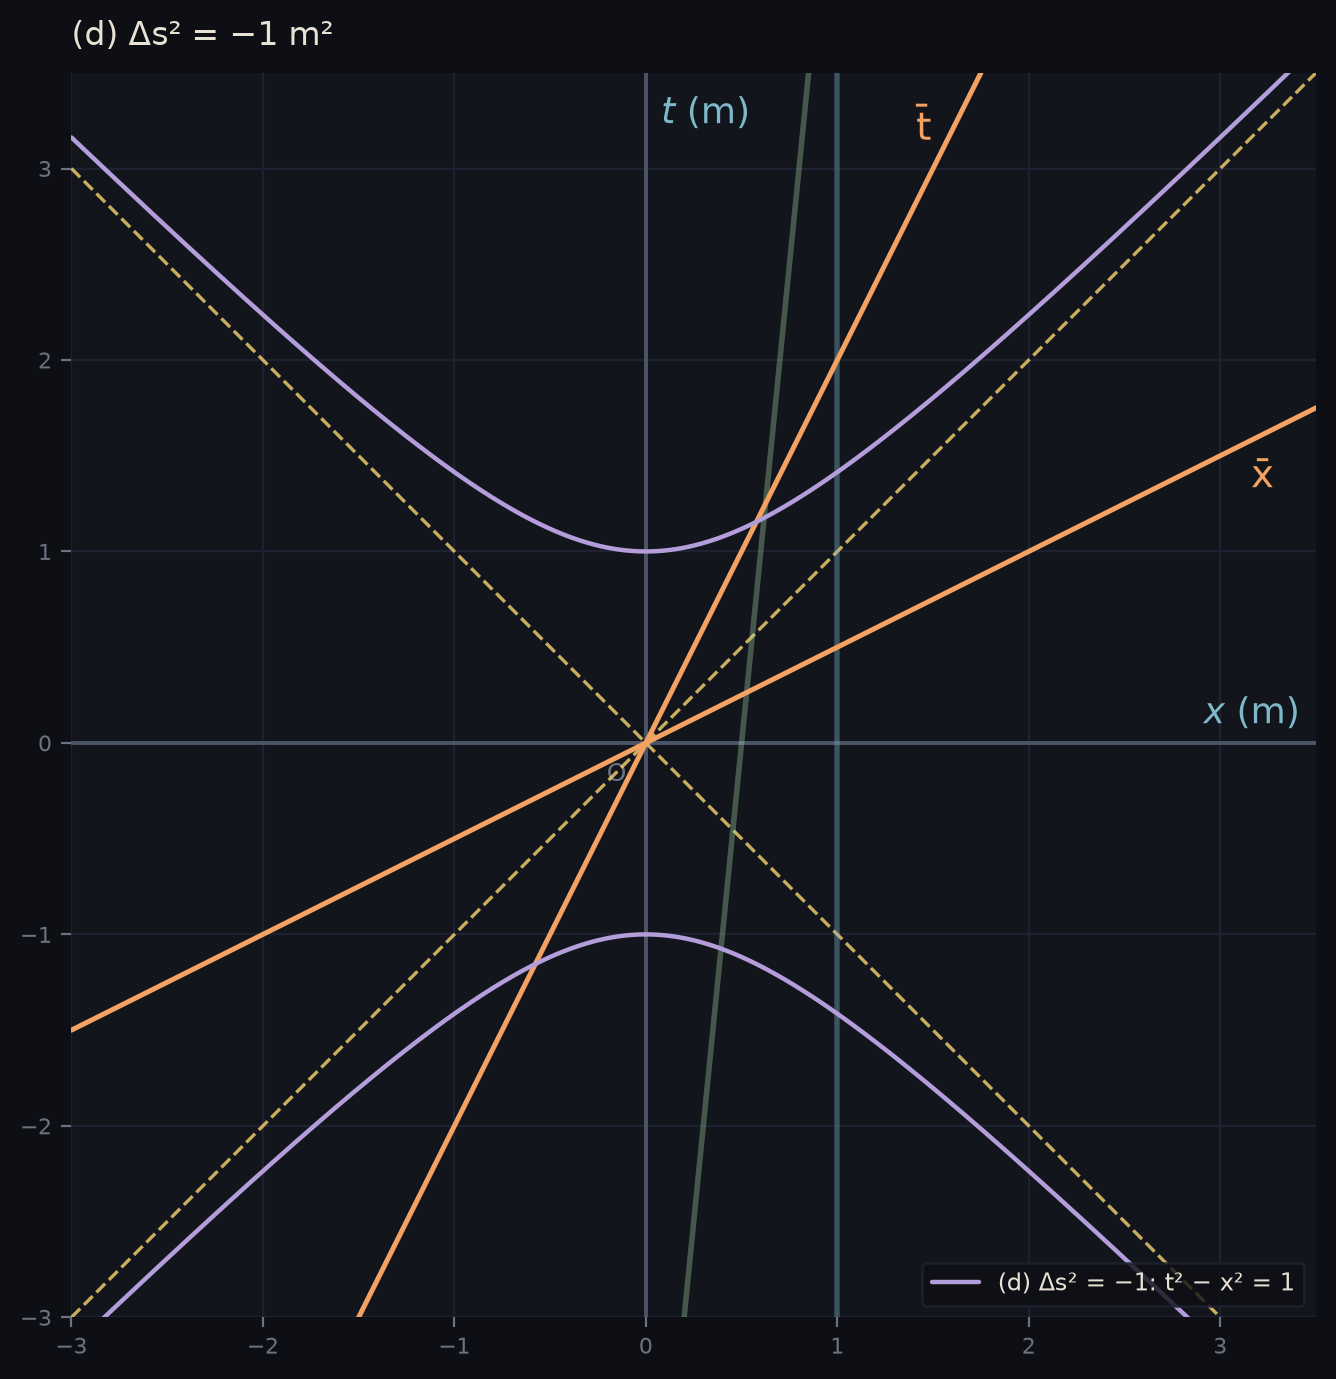

In [7]:
print("t̄² − x̄² =", sp.simplify(tb**2 - xb**2), " (identical to t² − x²: invariant)")
draw("abcdg", highlight="d", title="(d) Δs² = −1 m²").show()

## (e) Locus $\Delta s^2 = +1\ \text{m}^2$ from the origin

$$
-t^2 + x^2 = +1 \iff \boxed{x^2 - t^2 = 1},
$$

again a hyperbola with asymptotes $t = \pm x$, but opening sideways: branches $x = \pm\sqrt{1+t^2}$, vertices at $(t,x) = (0,\pm1)$ on $\mathcal O$'s $x$ axis. Every point is **spacelike** separated from the origin: some observer regards it as simultaneous with the origin and 1 m away (the proper distance is $\sqrt{\Delta s^2} = 1$ m).

(d) and (e) together are the **invariant hyperbolae**. They are the ruler-and-clock of Minkowski geometry: every inertial observer through the origin measures their own "1 m of time" where their time axis meets (d) and their "1 m of distance" where their space axis meets (e). That is exactly what part (f) uses.

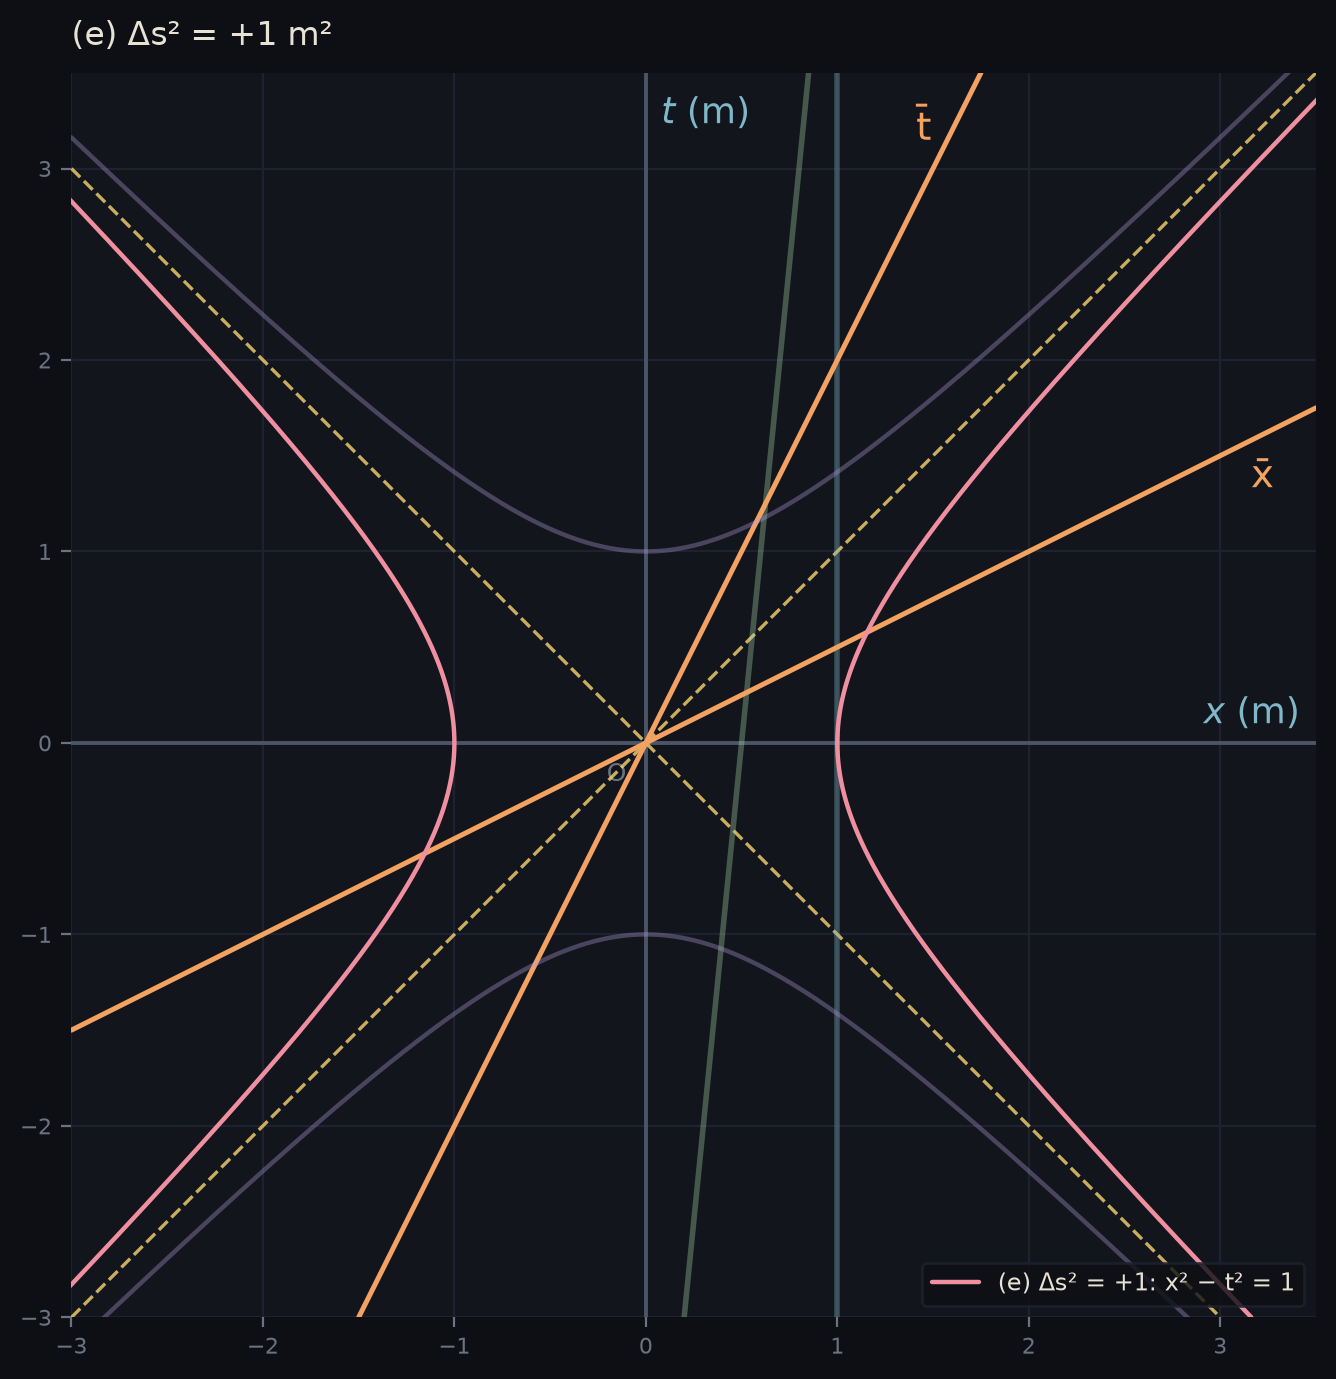

In [8]:
draw("abcdeg", highlight="e", title="(e) Δs² = +1 m²").show()

## (f) Calibration ticks on the $\bar t$ and $\bar x$ axes

**Tick $\bar t = 1$.** It is the event on the $\bar t$ axis ($x = vt$) with $\bar t = 1$, $\bar x = 0$, so $\Delta s^2 = -\bar t^2 + \bar x^2 = -1$. So it lies on the hyperbola (d). Solve the two equations together:

$$
x = v t,\quad t^2 - x^2 = 1 \;\Rightarrow\; t^2(1 - v^2) = 1 \;\Rightarrow\; t = \frac{1}{\sqrt{1-v^2}} = \gamma,\quad x = \gamma v.
$$

With $v = 0.5$: $\gamma = 2/\sqrt3 \approx 1.1547$, so the tick is at $(t, x) = (1.1547,\ 0.5774)$ in $\mathcal O$'s coordinates.

**Tick $\bar x = 1$.** On the $\bar x$ axis ($t = vx$) with $\Delta s^2 = +1$, the hyperbola (e):
$$
t = v x,\quad x^2 - t^2 = 1 \;\Rightarrow\; x = \gamma,\quad t = \gamma v \;\Rightarrow\; (t, x) = (0.5774,\ 1.1547).
$$

**All ticks.** The transformation is linear, so the $n$-th tick is $n$ times the first: $\bar t = n$ at $(\gamma n, \gamma v n)$ and $\bar x = n$ at $(\gamma v n, \gamma n)$. Equivalently these points lie on the hyperbolae $\Delta s^2 = \mp n^2$.

**Important:** On paper the $\bar{\mathcal O}$ ticks are spaced $\gamma\sqrt{1+v^2} = \sqrt{(1+v^2)/(1-v^2)} \approx 1.29$ times farther apart than $\mathcal O$'s, even though both represent 1 m. Paper distance is not spacetime distance.

t̄ = n ticks: [{t: 2*sqrt(3)*n/3, x: sqrt(3)*n/3}]
x̄ = n ticks: [{t: sqrt(3)*n/3, x: 2*sqrt(3)*n/3}]

t̄ = 1: (t, x) = (1.1547, 0.5774)     x̄ = 1: (t, x) = (0.5774, 1.1547)
t̄ = 2: (t, x) = (2.3094, 1.1547)     x̄ = 2: (t, x) = (1.1547, 2.3094)
t̄ = 3: (t, x) = (3.4641, 1.7321)     x̄ = 3: (t, x) = (1.7321, 3.4641)

paper spacing ratio γ·sqrt(1+v²) = 1.2910


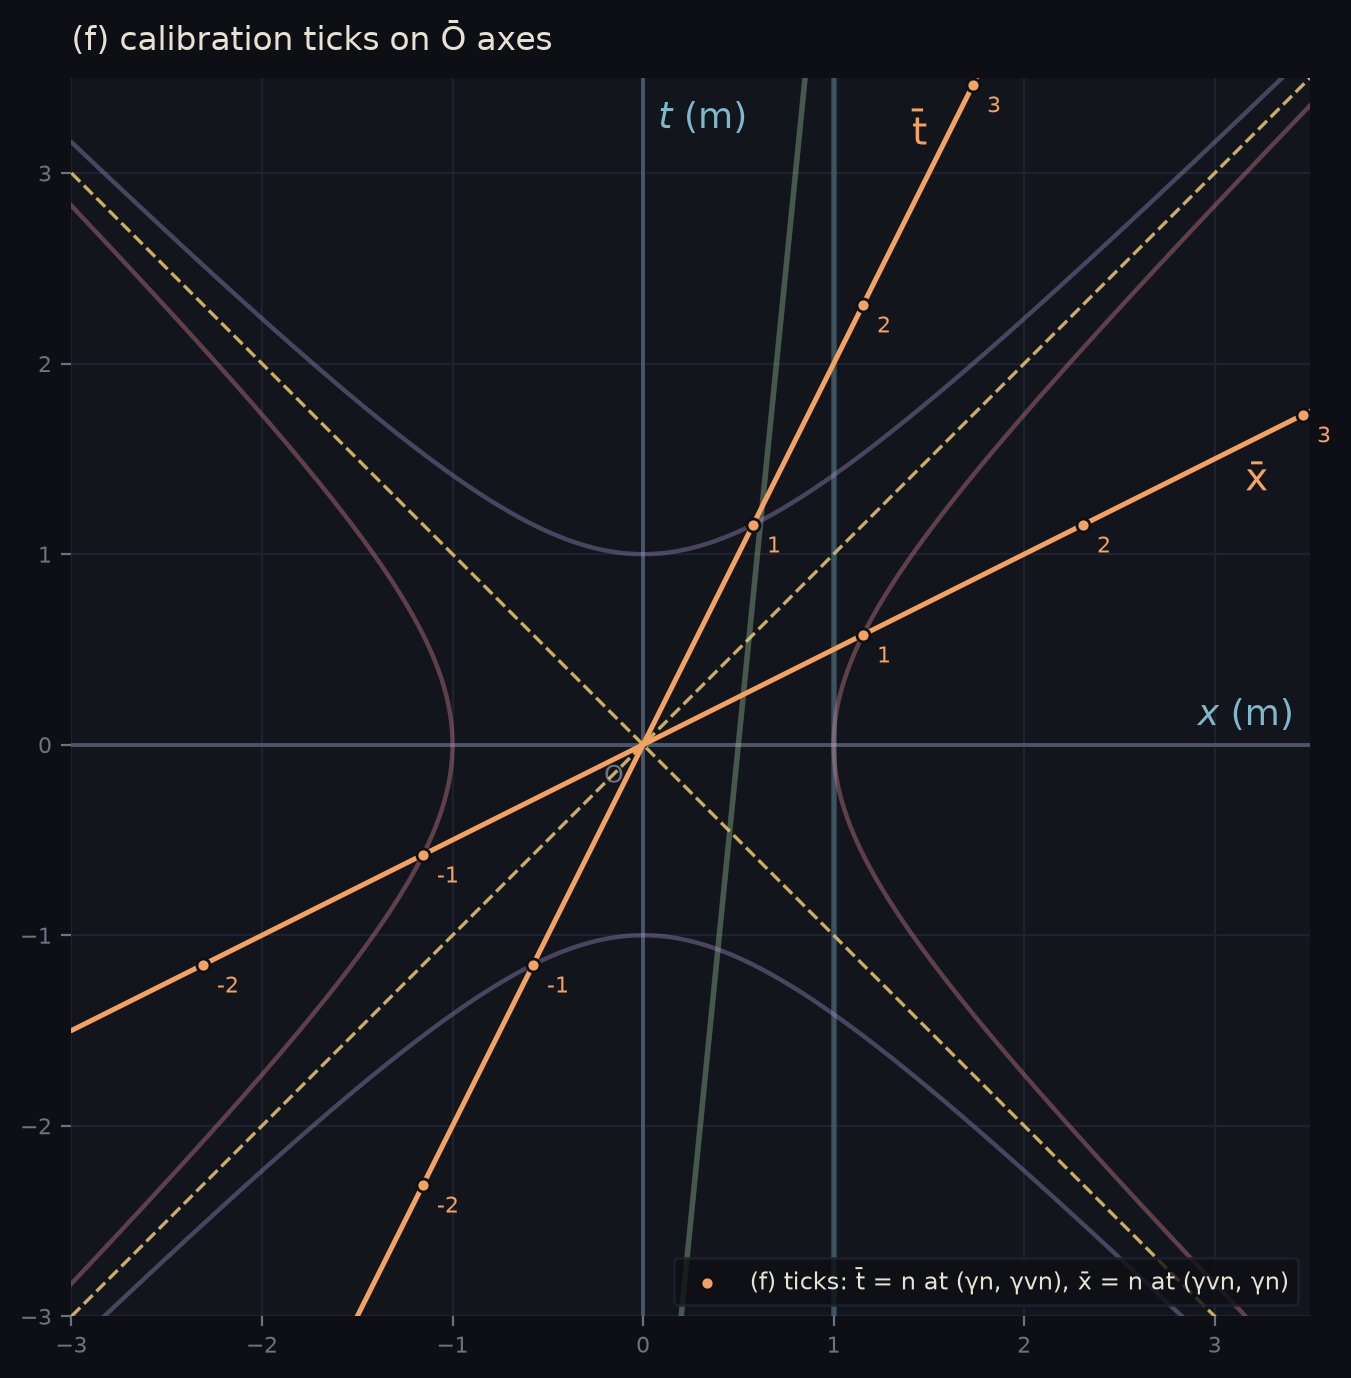

In [9]:
n = sp.symbols("n", positive=True)
sol_t = sp.solve([sp.Eq(x, v*t), sp.Eq(t**2 - x**2, n**2)], [t, x], dict=True)
sol_x = sp.solve([sp.Eq(t, v*x), sp.Eq(x**2 - t**2, n**2)], [t, x], dict=True)
print("t̄ = n ticks:", [s for s in sol_t if s[t] > 0])
print("x̄ = n ticks:", [s for s in sol_x if s[x] > 0])
print()
for k in (1, 2, 3):
    T, X = inverse_lorentz(k, 0, v); T2, X2 = inverse_lorentz(0, k, v)
    print(f"t̄ = {k}: (t, x) = ({float(T):.4f}, {float(X):.4f})     "
          f"x̄ = {k}: (t, x) = ({float(T2):.4f}, {float(X2):.4f})")
print(f"\npaper spacing ratio γ·sqrt(1+v²) = {float(g*sp.sqrt(1+v**2)):.4f}")
draw("abcdefg", highlight="f", title="(f) calibration ticks on Ō axes").show()

## (g) Locus $\Delta s^2 = 0$ from the origin

$$
-t^2 + x^2 = 0 \iff \boxed{t = \pm x}.
$$

Two straight lines at $45^\circ$: the **light cone** of the origin (in 1+1 dimensions, a pair of lines; with $y$ and $z$ it is the cone $t^2 = x^2 + y^2 + z^2$). These are the world lines of light rays through the origin moving in $+x$ and $-x$.

- Inside ($t^2 > x^2$, $\Delta s^2 < 0$): timelike — the future (upper) and past (lower) of the origin; can be causally connected to it.
- Outside ($\Delta s^2 > 0$): spacelike — "elsewhere"; no signal can connect them to the origin.

The light cone is the $\Delta s^2 = 0$ member of the family of hyperbolae in (d) and (e) — the degenerate case, and the common asymptote of all of them. Being invariant, it is the **same** for $\bar{\mathcal O}$: $\bar t = \pm\bar x$, which is why it bisects both pairs of axes.

light ray x = +t in Ō:  x̄/t̄ = 1
light ray x = -t in Ō:  x̄/t̄ = -1


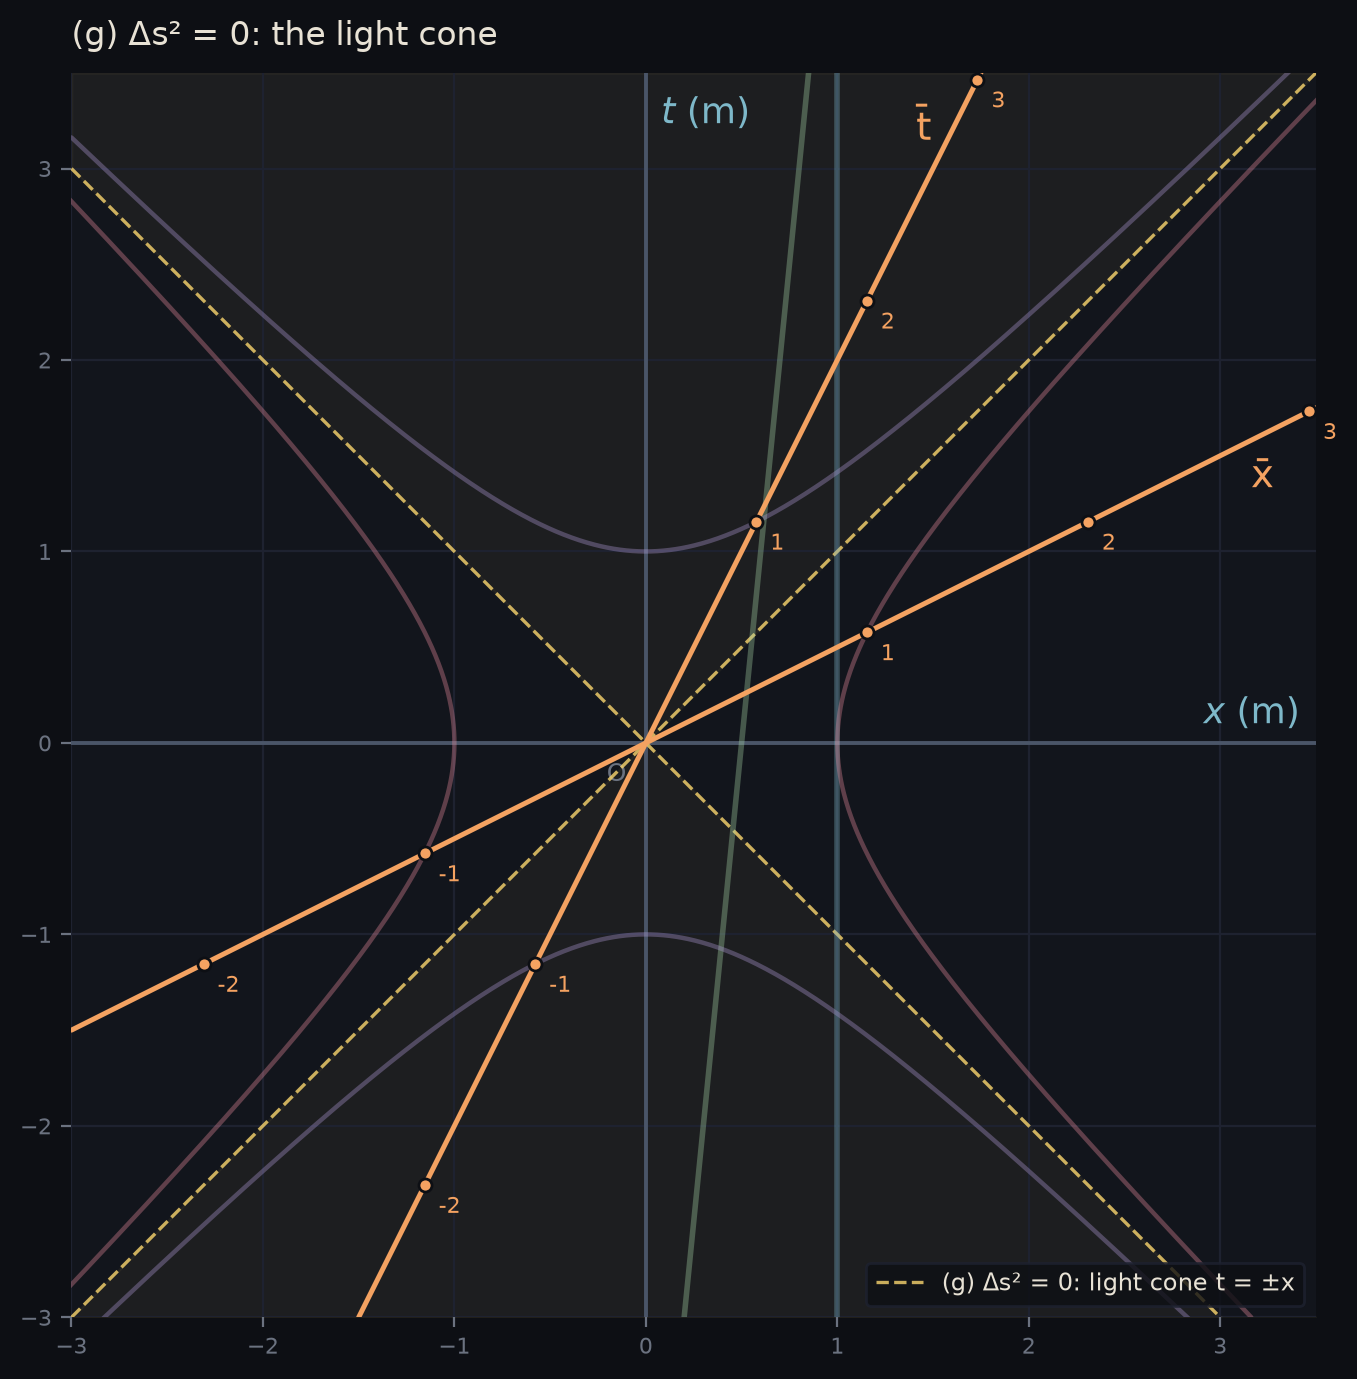

In [10]:
for s in (+1, -1):
    tb_, xb_ = lorentz(t, s*t, v)
    print(f"light ray x = {'+' if s>0 else '-'}t in Ō:  x̄/t̄ = {sp.simplify(xb_/tb_)}")
draw("abcdefg", highlight="g", title="(g) Δs² = 0: the light cone").show()

## (h) Events simultaneous for $\mathcal O$ at $t = 2\ \text{m}$

All events with the same $t$ coordinate:
$$
\boxed{t = 2\ \text{m}},\qquad x\ \text{arbitrary},
$$
a horizontal line, parallel to $\mathcal O$'s $x$ axis. $\mathcal O$'s lines of simultaneity are always parallel to the $x$ axis, because the $x$ axis *is* the line of simultaneity $t = 0$.

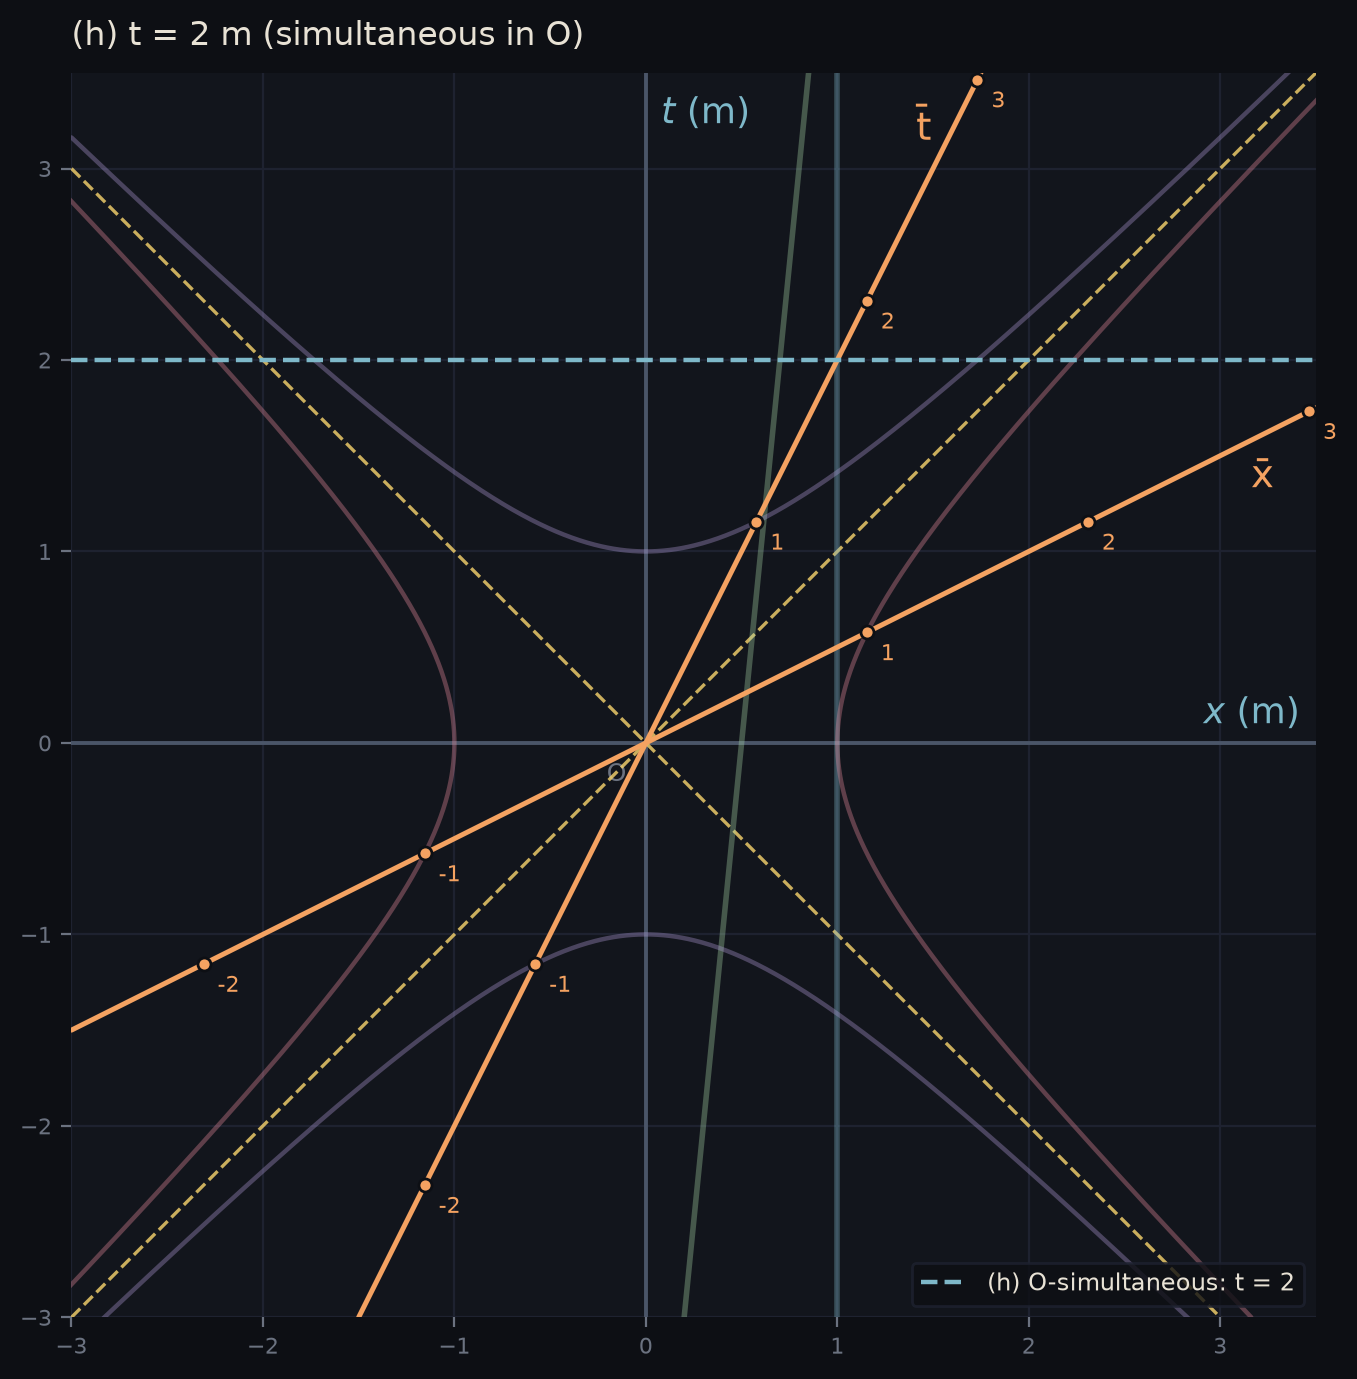

In [11]:
draw("abcdefgh", highlight="h", title="(h) t = 2 m (simultaneous in O)").show()

## (i) Events simultaneous for $\bar{\mathcal O}$ at $\bar t = 2\ \text{m}$

Set $\bar t = 2$ in the Lorentz transformation and solve for $t$ as a function of $x$:

$$
\gamma\,(t - v x) = 2 \;\Rightarrow\; t = v x + \frac{2}{\gamma} = 0.5\,x + 2\sqrt{1 - 0.25} = \boxed{0.5\,x + \sqrt3}\ \approx 0.5\,x + 1.732 .
$$

- **Slope** $dt/dx = v = 0.5$: parallel to the $\bar x$ axis, as every line of constant $\bar t$ must be.
- It crosses $\mathcal O$'s $t$ axis ($x=0$) at $t = \sqrt3 \approx 1.732$ m — *before* $t=2$.
- It crosses the $\bar t$ axis at the $\bar t = 2$ calibration tick, $(t, x) = (2\gamma, 2\gamma v) = (2.309, 1.155)$. ✓ (consistent with (f))

**Relativity of simultaneity.** Lines (h) and (i) meet at one event only:
$$
2 = 0.5x + \sqrt3 \;\Rightarrow\; x = 2(2 - \sqrt3) \approx 0.536\ \text{m}.
$$
At every other place, the two observers disagree about which events are "at time 2". E.g. at $x = 3$ m, $\mathcal O$'s "now" is $t = 2$ but $\bar{\mathcal O}$'s $\bar t = 2$ surface passes through $t = 1.5 + \sqrt3 \approx 3.23$ m.

(i):  t = x/2 + sqrt(3) ≈ 0.5*x + 1.732
(h)∩(i) at x = 4 - 2*sqrt(3) ≈ 0.53590 m
t̄ = 2 tick on t̄ axis: (t, x) = (2.3094, 1.1547)  lies on (i): True


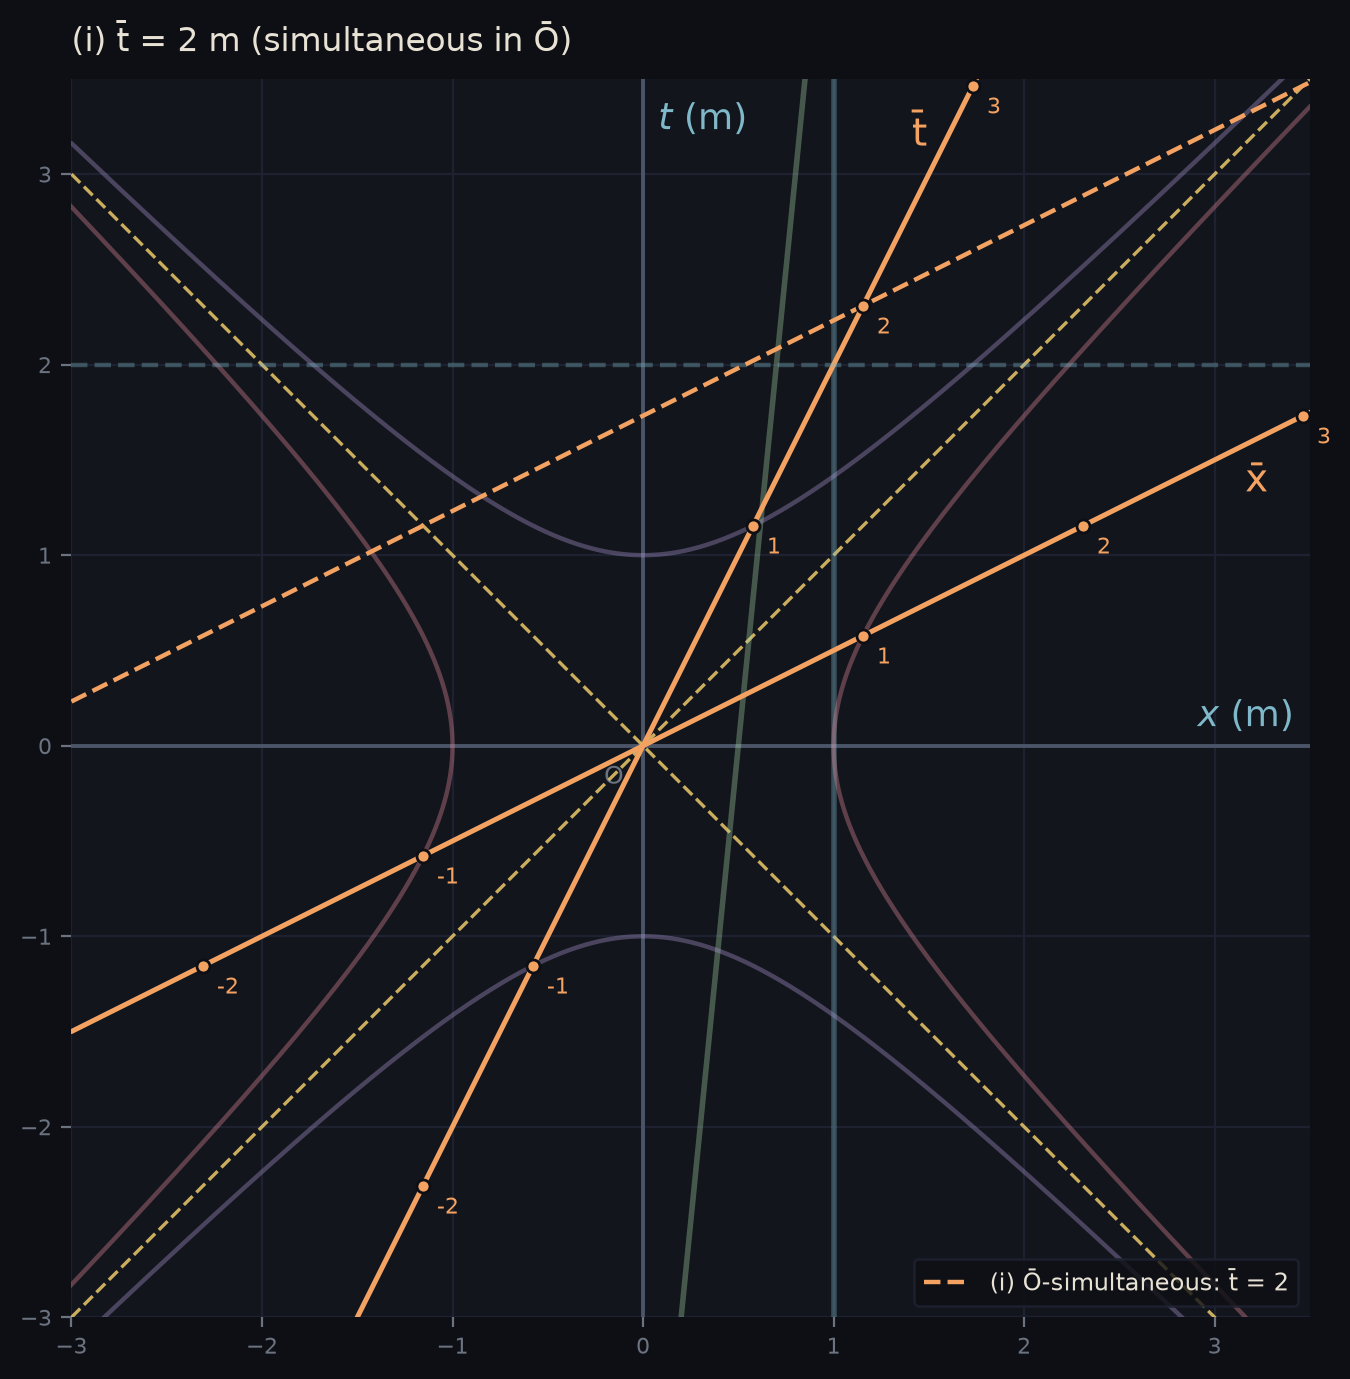

In [12]:
line_i = sp.solve(sp.Eq(tb, 2), t)[0]
print("(i):  t =", sp.simplify(line_i), "≈", sp.N(line_i, 5))
x_cross = sp.solve(sp.Eq(line_i, 2), x)[0]
print("(h)∩(i) at x =", sp.simplify(x_cross), "≈", sp.N(x_cross, 5), "m")
T, X = inverse_lorentz(2, 0, v)
print("t̄ = 2 tick on t̄ axis: (t, x) =", (sp.N(T, 5), sp.N(X, 5)), " lies on (i):", sp.simplify(line_i.subs(x, X) - T) == 0)
draw("abcdefghi", highlight="i", title="(i) t̄ = 2 m (simultaneous in Ō)").show()

## (j) The event $\bar t = 0$, $\bar x = 0.5\ \text{m}$

Use the **inverse** transformation (swap barred/unbarred and $v \to -v$):
$$
t = \gamma(\bar t + v\bar x),\qquad x = \gamma(\bar x + v\bar t).
$$

Substitute $\bar t = 0$, $\bar x = 0.5$, $v = 0.5$, $\gamma = 2/\sqrt3$:
$$
t = \frac{2}{\sqrt3}(0 + 0.25) = \frac{1}{2\sqrt3} \approx 0.2887\ \text{m},\qquad
x = \frac{2}{\sqrt3}(0.5 + 0) = \frac{1}{\sqrt3} \approx 0.5774\ \text{m}.
$$

$$
\boxed{(t, x) = \left(\tfrac{1}{2\sqrt3},\ \tfrac{1}{\sqrt3}\right) \approx (0.289,\ 0.577)\ \text{m}}
$$

**Checks.**
- It lies on the $\bar x$ axis: $t = 0.5\,x$ ✓ ($0.2887 = 0.5\times0.5774$).
- It is halfway to the $\bar x = 1$ tick of (f), $(0.577, 1.155)$ ✓ (linearity).
- Interval from origin: $-t^2 + x^2 = -\tfrac1{12} + \tfrac13 = \tfrac14 = (0.5)^2 = \bar x^2$ ✓ — the proper distance is $\bar{\mathcal O}$'s $0.5$ m.

Note $t > 0$: the event is *later than* the origin for $\mathcal O$ but simultaneous with it for $\bar{\mathcal O}$.

(j): t = sqrt(3)/6 ≈ 0.28868    x = sqrt(3)/3 ≈ 0.57735
on x̄ axis (t = x/2): True
Δs² from origin = 1/4


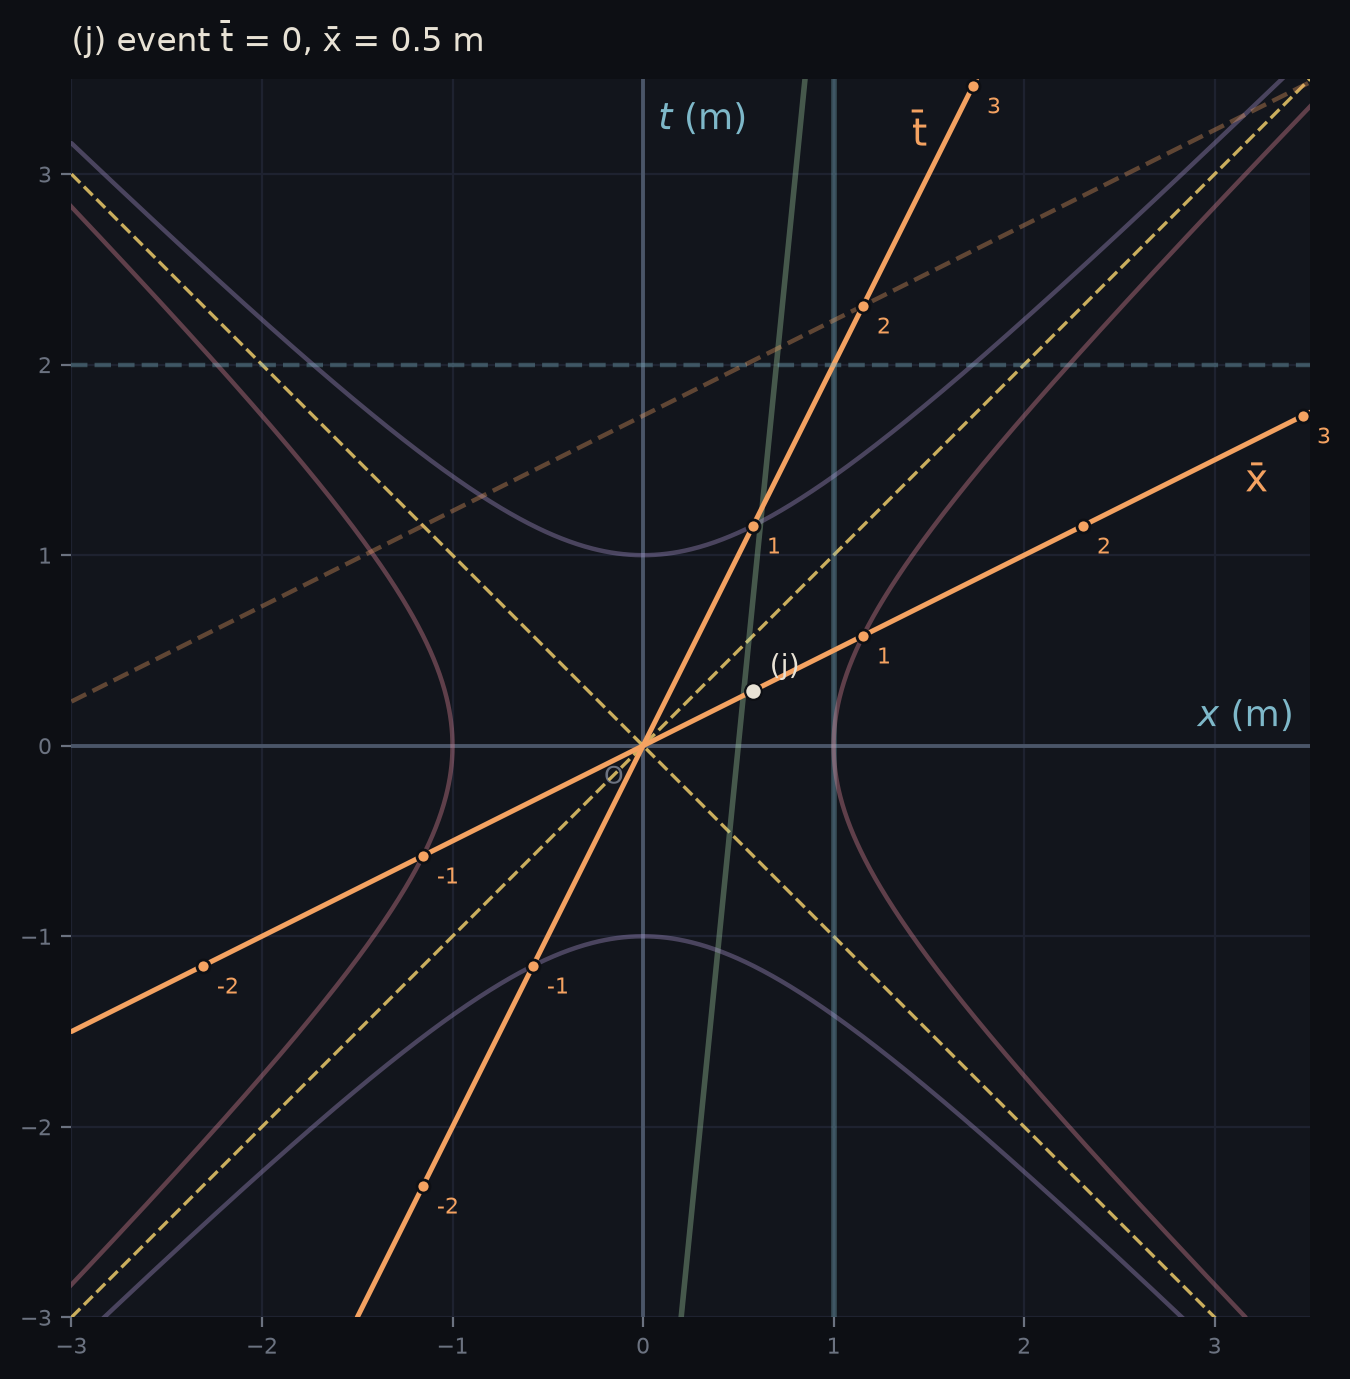

In [13]:
Tj, Xj = inverse_lorentz(0, sp.Rational(1, 2), v)
print("(j): t =", sp.nsimplify(Tj), "≈", sp.N(Tj, 5), "   x =", sp.nsimplify(Xj), "≈", sp.N(Xj, 5))
print("on x̄ axis (t = x/2):", sp.simplify(Tj - Xj/2) == 0)
print("Δs² from origin =", sp.simplify(interval_tx(Tj, Xj)))
draw("abcdefghij", highlight="j", title="(j) event t̄ = 0, x̄ = 0.5 m").show()

## (k) The locus $\bar x = 1\ \text{m}$

These are all the events at $\bar{\mathcal O}$'s spatial position $\bar x = 1$ — the world line of $\bar{\mathcal O}$'s clock at $\bar x = 1$. Set $\bar x = 1$ in the Lorentz transformation:
$$
\gamma\,(x - v t) = 1 \;\Rightarrow\; x = v t + \frac{1}{\gamma} = \boxed{0.5\,t + \tfrac{\sqrt3}{2}}\ \approx 0.5\,t + 0.866 .
$$

- It's **parallel to the $\bar t$ axis** (slope $dx/dt = v = 0.5$): a clock at rest in $\bar{\mathcal O}$ moves with $\bar{\mathcal O}$. It's the $\bar{\mathcal O}$-analogue of part (a).
- At $t = 0$ it's at $x = \sqrt3/2 \approx 0.866$, *less* than 1. In $\mathcal O$'s frame (at $t=0$) the 1 m separation between $\bar{\mathcal O}$'s origin clock and this clock is Lorentz-contracted to $\sqrt{1-v^2} = 0.866$ m.
- It passes through the $\bar x = 1$ calibration tick of (f), $(t,x) = (0.577, 1.155)$ ✓ — where it crosses the $\bar x$ axis.

(k):  x = t/2 + sqrt(3)/2 ≈ 0.5*t + 0.866
passes through x̄ = 1 tick (t, x) = (0.5773, 1.155) : True


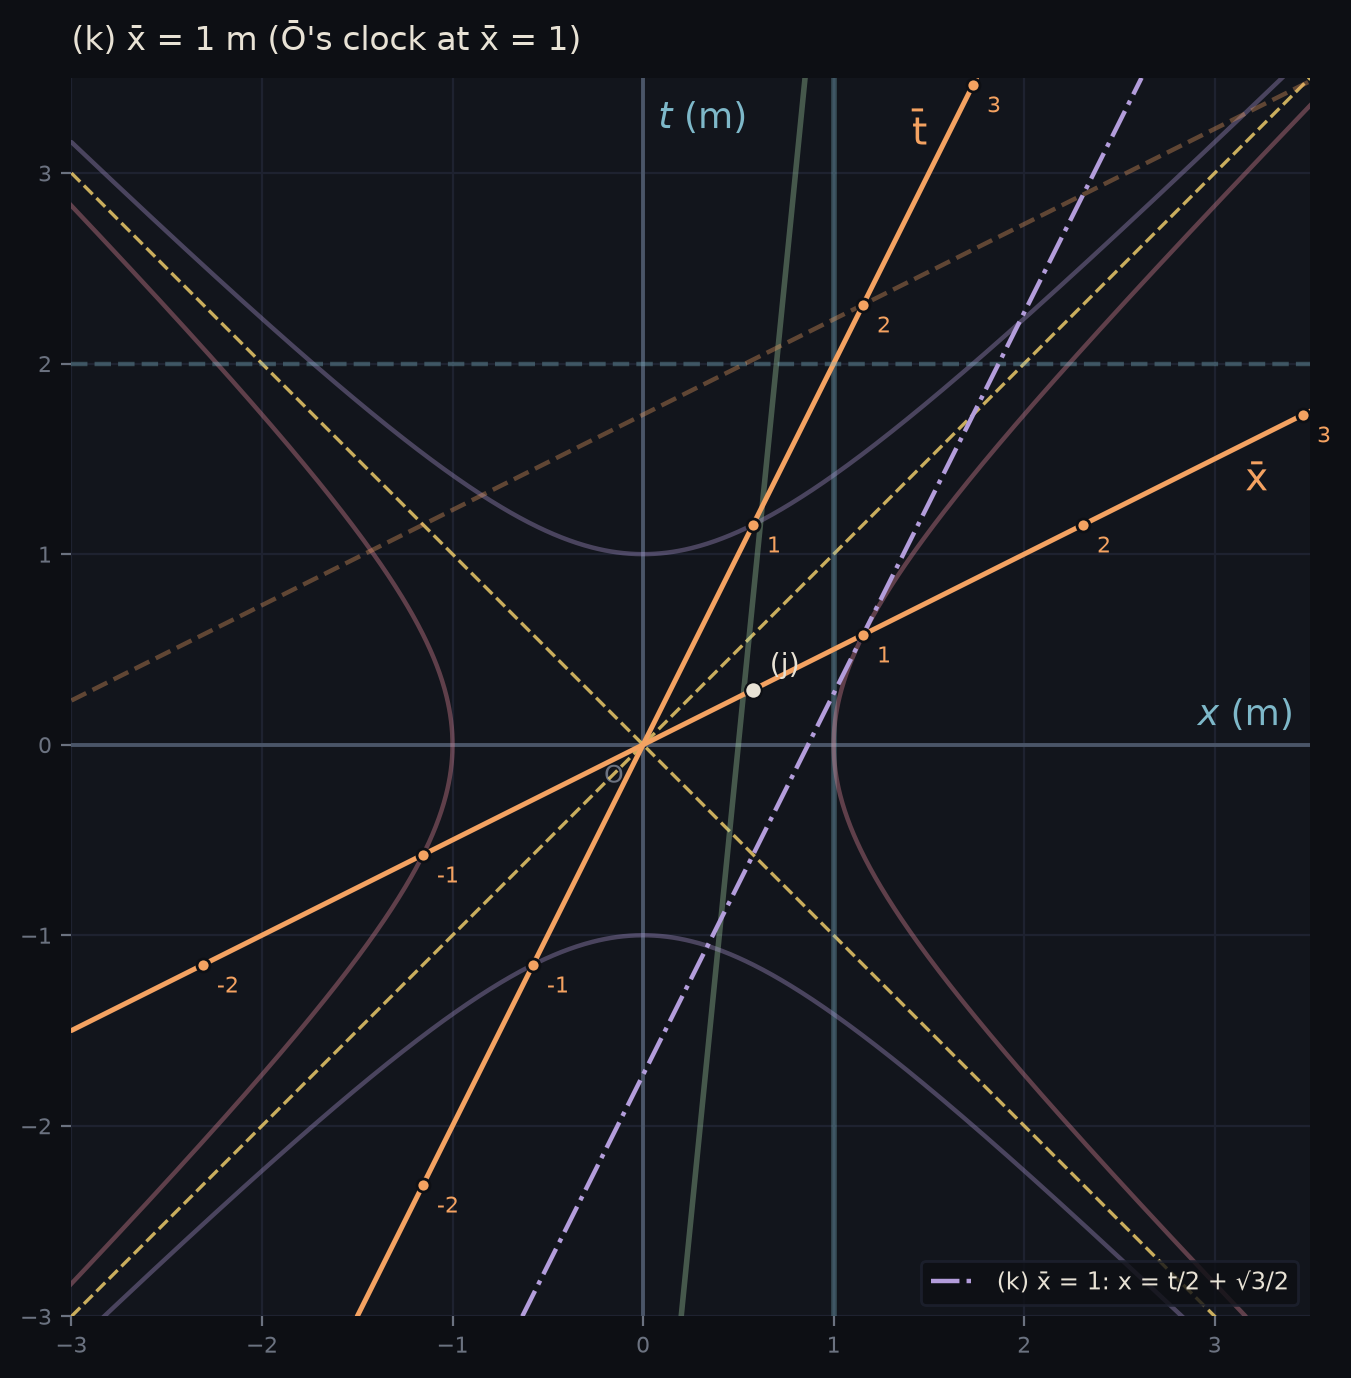

In [14]:
line_k = sp.solve(sp.Eq(xb, 1), x)[0]
print("(k):  x =", sp.simplify(line_k), "≈", sp.N(line_k, 4))
T1, X1 = inverse_lorentz(0, 1, v)
print("passes through x̄ = 1 tick (t, x) =", (sp.N(T1, 4), sp.N(X1, 4)), ":", sp.simplify(line_k.subs(t, T1) - X1) == 0)
draw("abcdefghijk", highlight="k", title="(k) x̄ = 1 m (Ō's clock at x̄ = 1)").show()

## (l) A photon bounced off a moving mirror

**The world lines involved (all in $\mathcal O$'s coordinates):**
- The **mirror** is at $\bar x = -1$, at rest in $\bar{\mathcal O}$. As in (k): $\gamma(x - vt) = -1 \Rightarrow x_M(t) = 0.5\,t - \tfrac{\sqrt3}{2}$. It moves at $+0.5$.
- The **detector** is at $x = 0.75$, at rest in $\mathcal O$: a vertical line.
- The **photon** is emitted at $(t, x) = (-1, 0)$ moving in $-x$: $x = -(t + 1)$.

**Reflection event.** Set the photon equal to the mirror:
$$
-(t + 1) = \tfrac12 t - \tfrac{\sqrt3}{2} \;\Rightarrow\; -\tfrac32 t = 1 - \tfrac{\sqrt3}{2} \;\Rightarrow\; t_R = \frac{\sqrt3 - 2}{3} \approx -0.0893,\qquad x_R = -(t_R + 1) = -\frac{\sqrt3 + 1}{3} \approx -0.9107 .
$$

**After reflection** the photon moves in $+x$ — still at speed 1. A moving mirror can Doppler-shift light but can't change its speed (§1.5, universality of $c$). So $x = x_R + (t - t_R)$.

**Absorption at the detector** $x = 0.75$:
$$
t_D = t_R + (0.75 - x_R) = \frac{\sqrt3 - 2}{3} + \frac34 + \frac{\sqrt3 + 1}{3} = \frac{2\sqrt3 - 1}{3} + \frac34 = \frac{8\sqrt3 + 5}{12} \approx 1.5714 .
$$

$$
\boxed{\text{emit }(-1,\ 0)\ \to\ \text{reflect }\left(\tfrac{\sqrt3-2}{3},\ -\tfrac{\sqrt3+1}{3}\right)\approx(-0.089,\ -0.911)\ \to\ \text{absorb }\left(\tfrac{8\sqrt3+5}{12},\ 0.75\right)\approx(1.571,\ 0.75)}
$$

**Check in $\bar{\mathcal O}$'s frame.** The reflection event should have $\bar x = -1$: $\bar x_R = \gamma(x_R - v t_R) = -1$ ✓ (code below). And both legs have $|\Delta\bar x/\Delta\bar t| = 1$ ✓ — light moves at speed 1 for $\bar{\mathcal O}$ too. The reflection happens a little *before* $t = 0$, because the mirror is moving toward the photon (it starts at $x = -0.866$ at $t = 0$ and was farther left earlier).

mirror: x = t/2 - sqrt(3)/2
reflect: t = -2/3 + sqrt(3)/3 ≈ -0.08932   x = -sqrt(3)/3 - 1/3 ≈ -0.9107
absorb:  t = 5/12 + 2*sqrt(3)/3 ≈ 1.5714   x = 0.75
reflection in Ō: x̄ = -1
photon speed in Ō on this leg: -1
photon speed in Ō on this leg: 1


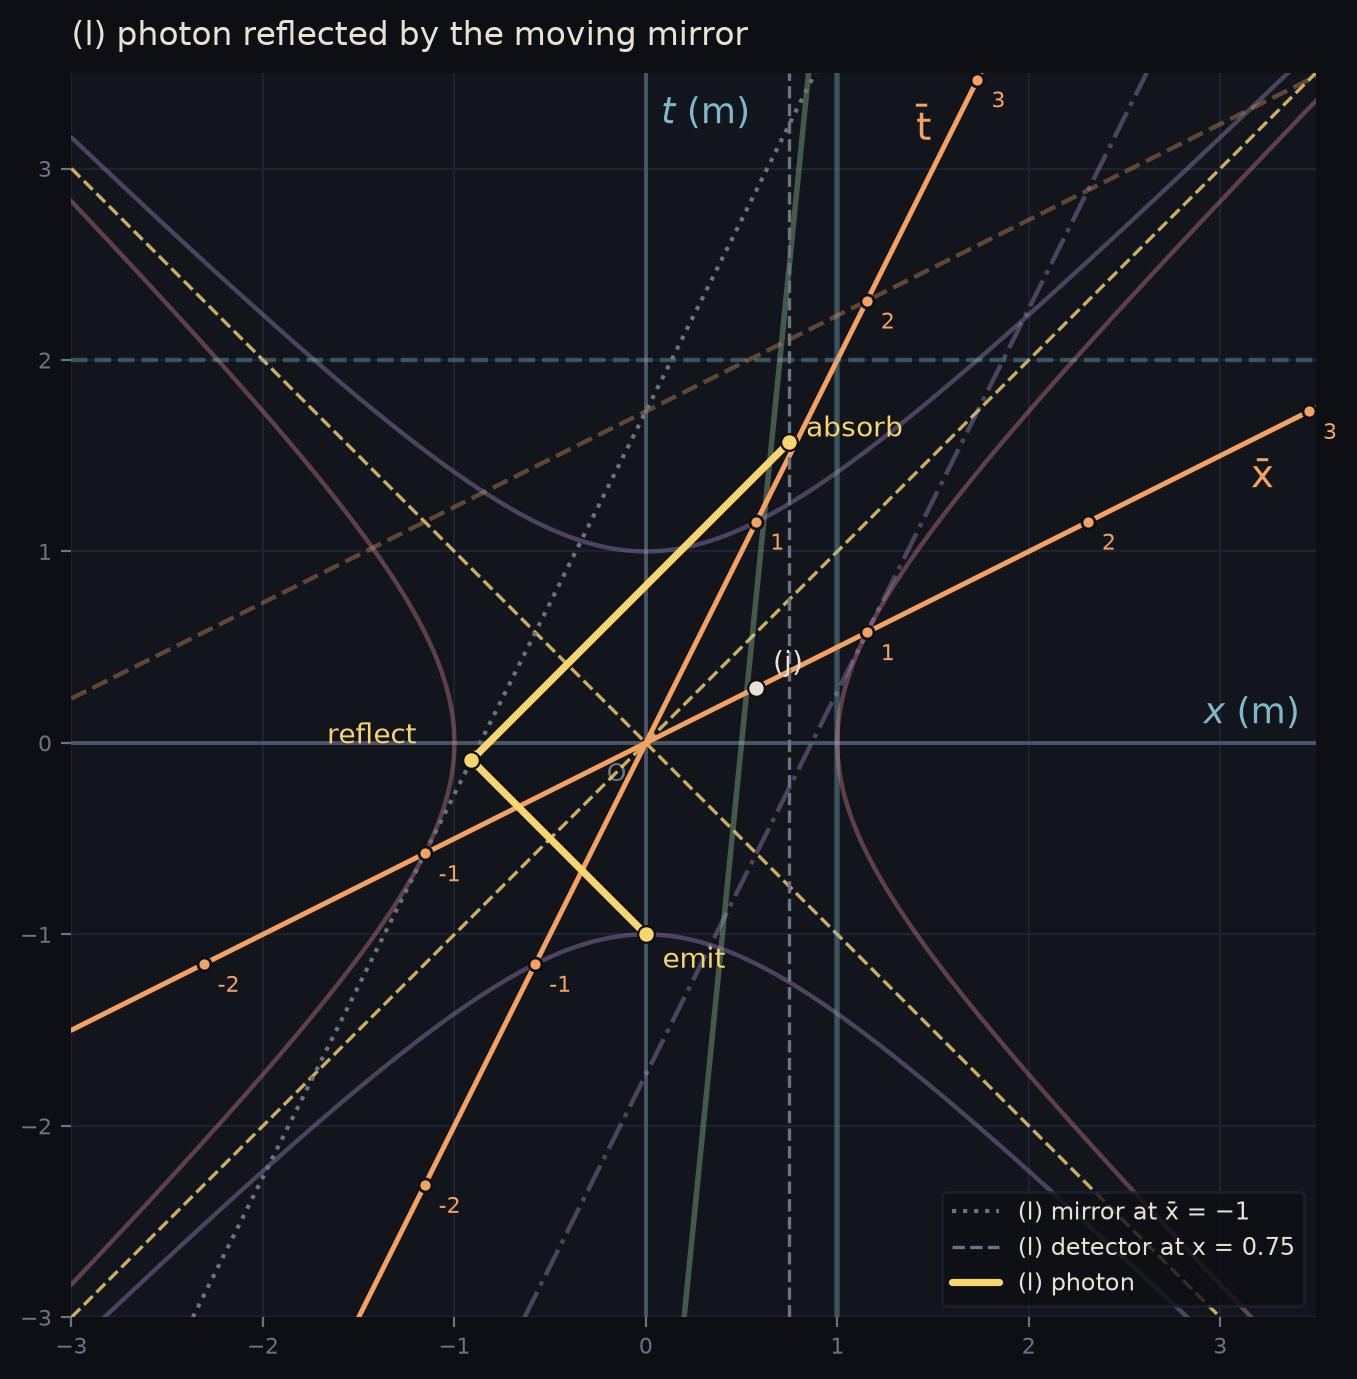

In [15]:
r3 = sp.sqrt(3)
xM = sp.solve(sp.Eq(xb, -1), x)[0]                          # mirror world line x(t)
tR = sp.solve(sp.Eq(-(t + 1), xM), t)[0]; xR = sp.simplify(-(tR + 1))
tD = sp.simplify(tR + (sp.Rational(3, 4) - xR))
print("mirror: x =", sp.simplify(xM))
print("reflect: t =", sp.nsimplify(tR), "≈", sp.N(tR, 4), "  x =", sp.nsimplify(xR), "≈", sp.N(xR, 4))
print("absorb:  t =", sp.nsimplify(tD), "≈", sp.N(tD, 5), "  x = 0.75")
tbR, xbR = lorentz(tR, xR, v)
print("reflection in Ō: x̄ =", sp.simplify(xbR))
for (ta, xa), (tc, xc) in (((-1, 0), (tR, xR)), ((tR, xR), (tD, sp.Rational(3, 4)))):
    A, C = lorentz(ta, xa, v), lorentz(tc, xc, v)
    print("photon speed in Ō on this leg:", sp.simplify((C[1] - A[1]) / (C[0] - A[0])))
draw("abcdefghijkl", highlight="l", title="(l) photon reflected by the moving mirror").show()

## The complete diagram

All twelve parts together, with the key events labelled.

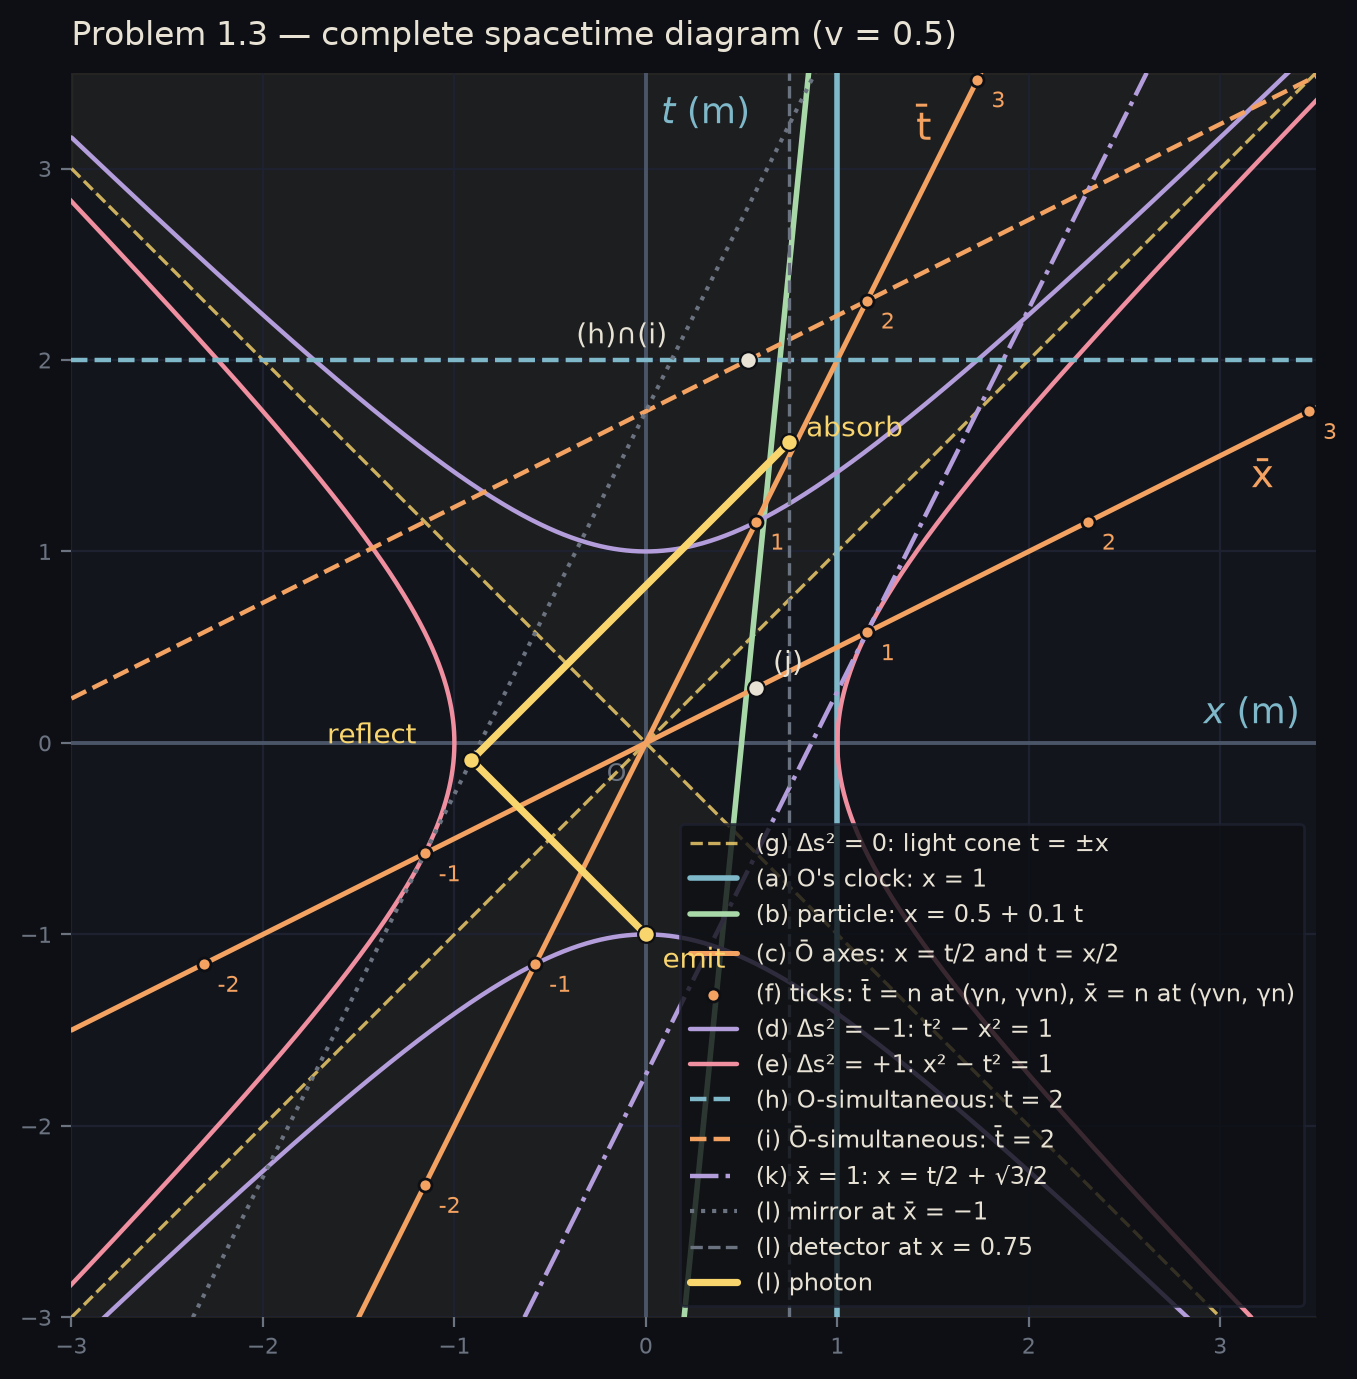

In [16]:
d = draw(ORDER, title="Problem 1.3 — complete spacetime diagram (v = 0.5)")
d.event(2.0, 2*(2-np.sqrt(3)), name="(h)∩(i)", color="text", offset=(-62, 6))
d.show(loc="lower right")

## Summary

| part | locus / event | equation in $\mathcal O$'s coordinates |
|---|---|---|
| (a) | clock at rest | $x = 1$ |
| (b) | particle, $v=0.1$ | $x = 0.5 + 0.1t$ |
| (c) | $\bar t$ axis / $\bar x$ axis | $x = 0.5t$ / $t = 0.5x$ |
| (d) | $\Delta s^2 = -1$ | $t^2 - x^2 = 1$ |
| (e) | $\Delta s^2 = +1$ | $x^2 - t^2 = 1$ |
| (f) | ticks $\bar t = n$, $\bar x = n$ | $(\gamma n, \gamma v n)$, $(\gamma v n, \gamma n)$, $\gamma = 2/\sqrt3$ |
| (g) | $\Delta s^2 = 0$ | $t = \pm x$ |
| (h) | $t = 2$ | $t = 2$ |
| (i) | $\bar t = 2$ | $t = 0.5x + \sqrt3$ |
| (j) | $\bar t = 0,\ \bar x = 0.5$ | $(t,x) = (0.289,\ 0.577)$ |
| (k) | $\bar x = 1$ | $x = 0.5t + \sqrt3/2$ |
| (l) | photon | $(-1, 0) \to (-0.089, -0.911) \to (1.571, 0.75)$ |